In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

In [2]:
import matplotlib.pyplot as plt

MONO_BLACK = "0.00"
MONO_DARK = "0.30"
MONO_MID = "0.55"
MONO_LIGHT = "0.82"

/Users/hiroshi/private/marketing_science/envs/py314-main/.venv/lib/python3.14/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (1.26.13) or chardet (7.4.3)/charset_normalizer (2.1.1) doesn't match a supported version!
  warnings.warn(


# 第7章 解約を予測する


## 第7章、第3節、第1項のコード

### データの読み込み

IBM Telco Customer Churn Dataset（7,043 名の顧客）を Polars で読み込み、生存時間解析と解約スコアの算出に必要な主な11列を取り出して先頭5行を確認する。

出典: IBM, [Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv)。配布元の説明では、サンプルコードは [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0) で公開されている。CSVのライセンスは別には書かれていない。

#### 処理内容

1. **ライブラリの読み込み**
   `polars` と `numpy` を読み込む。

2. **使用列の定義**
   `customerID`、`tenure`、`Churn` など主な11列を `USE_COLS` リストで指定する。

3. **CSV ファイルの読み込み**
   `pl.read_csv()` で `./data/Telco-Customer-Churn.csv` を読み込み、`select()` で必要な列だけを取り出す。

4. **先頭データの確認**
   `df_raw.head(5)` でデータの構造と内容を確認する。


In [3]:
import numpy as np
import polars as pl

# 表7.3の主な項目のみ読み込む
USE_COLS = [
    "customerID",
    "tenure",
    "Churn",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "SeniorCitizen",
    "Partner",
    "TechSupport",
]

df_raw = pl.read_csv("./data/Telco-Customer-Churn.csv").select(USE_COLS)

print(f"行数: {df_raw.height}, 列数: {df_raw.width}")
df_raw_head = df_raw.head(5)

# 本文掲載用には主な5列だけを表示する
df_raw_head_display = df_raw_head.select(
    ["customerID", "tenure", "Churn", "MonthlyCharges", "TotalCharges"]
)
df_raw_head

行数: 7043, 列数: 11


customerID,tenure,Churn,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod,SeniorCitizen,Partner,TechSupport
str,i64,str,f64,f64,str,str,str,i64,str,str
"""7590-VHVEG""",1,"""No""",29.85,29.85,"""Month-to-month""","""DSL""","""Electronic check""",0,"""Yes""","""No"""
"""5575-GNVDE""",34,"""No""",56.95,1889.5,"""One year""","""DSL""","""Mailed check""",0,"""No""","""No"""
"""3668-QPYBK""",2,"""Yes""",53.85,108.15,"""Month-to-month""","""DSL""","""Mailed check""",0,"""No""","""No"""
"""7795-CFOCW""",45,"""No""",42.3,1840.75,"""One year""","""DSL""","""Bank transfer (automatic)""",0,"""No""","""Yes"""
"""9237-HQITU""",2,"""Yes""",70.7,151.65,"""Month-to-month""","""Fiber optic""","""Electronic check""",0,"""No""","""No"""


## 第7章、第3節、第1項のコード

### データの整理

`Churn` を0/1に、`SeniorCitizen` をTrueまたはFalseに変換し、解約率を確認する。`TotalCharges` の欠損は、モデルで同列を使わないため削除しない。

#### 処理内容

1. **解約の有無を表す列の作成**
   `Churn == "Yes"` を 1、それ以外を 0 とした `churn_flag` 列を追加する。

2. **`SeniorCitizen` の変換**
   整数型をTrueまたはFalseに変換する。


In [4]:
# データを整理
df = df_raw.with_columns(
    # Churnを0/1に変換（1=解約, 0=継続）
    pl.when(pl.col("Churn") == "Yes").then(1).otherwise(0).alias("churn_flag"),
    # SeniorCitizenをTrueまたはFalseに変換
    pl.col("SeniorCitizen").cast(pl.Boolean),
)

print(f"整理後の行数: {df.height}")
print(f"解約率: {df['churn_flag'].mean():.3f} ({df['churn_flag'].sum()}件)")

整理後の行数: 7043
解約率: 0.265 (1869件)


## 第7章、第3節、第1項のコード

### 生存時間解析に使う変数の確認

生存時間 `T`（`tenure`）と、解約した場合は1、継続中の場合は0となる `E`（`churn_flag`）を取り出し、分布と契約形態ごとの解約率を確認する。

#### 処理内容

1. **変数の取り出し**
   `tenure` を生存時間 `T`、`churn_flag` を解約した場合は1、継続中の場合は0となる `E` としてNumPyの配列に変換する。

2. **分布の確認**
   最小・最大・中央値を出力し、イベント件数と打ち切り件数を確認する。

3. **契約形態ごとの集計**
   `group_by("Contract")` で顧客数・解約率・平均在籍月数を集計し、解約率の高い順に並べる。


In [5]:
# 生存時間解析に使う変数の確認
T = df["tenure"].to_numpy()  # 生存時間 t_i
E = df["churn_flag"].to_numpy()  # 解約=1、継続中=0（delta_i）

print("生存時間（tenure）の分布:")
print(
    f"  最小: {T.min()}か月, 最大: {T.max()}か月, 中央値: {np.median(T):.0f}か月"
)
print(f"\nイベント（解約）の件数: {E.sum()} / {len(E)}")
print(f"打ち切り（継続中）の件数: {(E == 0).sum()} / {len(E)}")

# 契約形態ごとの解約率を確認
print("\n契約形態ごとの解約率:")
churn_by_contract = (
    df.group_by("Contract")
    .agg(
        [
            pl.len().alias("顧客数"),
            pl.col("churn_flag").mean().alias("解約率"),
            pl.col("tenure").mean().alias("平均在籍月数"),
        ]
    )
    .sort("解約率", descending=True)
    .with_columns(pl.col(["解約率", "平均在籍月数"]).round(3))
)
churn_display = churn_by_contract.with_columns(
    pl.col("Contract").replace(
        {
            "Month-to-month": "月次契約",
            "One year": "1年契約",
            "Two year": "2年契約",
        }
    )
).rename({"Contract": "契約形態", "平均在籍月数": "平均月数"})
churn_by_contract

生存時間（tenure）の分布:
  最小: 0か月, 最大: 72か月, 中央値: 29か月

イベント（解約）の件数: 1869 / 7043
打ち切り（継続中）の件数: 5174 / 7043

契約形態ごとの解約率:


Contract,顧客数,解約率,平均在籍月数
str,u32,f64,f64
"""Month-to-month""",3875,0.427,18.037
"""One year""",1473,0.113,42.045
"""Two year""",1695,0.028,56.735


## 第7章、第3節、第2項のコード

### 全体のカプラン・マイヤー曲線

全顧客を対象にカプラン・マイヤー曲線を推定し、各時点の生存確率を確認する。

#### 処理内容

1. **カプラン・マイヤー曲線の推定**
   `lifelines` の `KaplanMeierFitter` を使い、生存時間 `T` と解約の有無を表す `E` から曲線を推定する。

2. **生存確率の確認**
   12・24・36か月時点の生存確率を出力する。

3. **曲線の描画**
   信頼区間付きのカプラン・マイヤー曲線を描画する。


カプラン・マイヤー推定の概要:
  12か月生存確率: 0.843
  24か月生存確率: 0.789
  36か月生存確率: 0.749


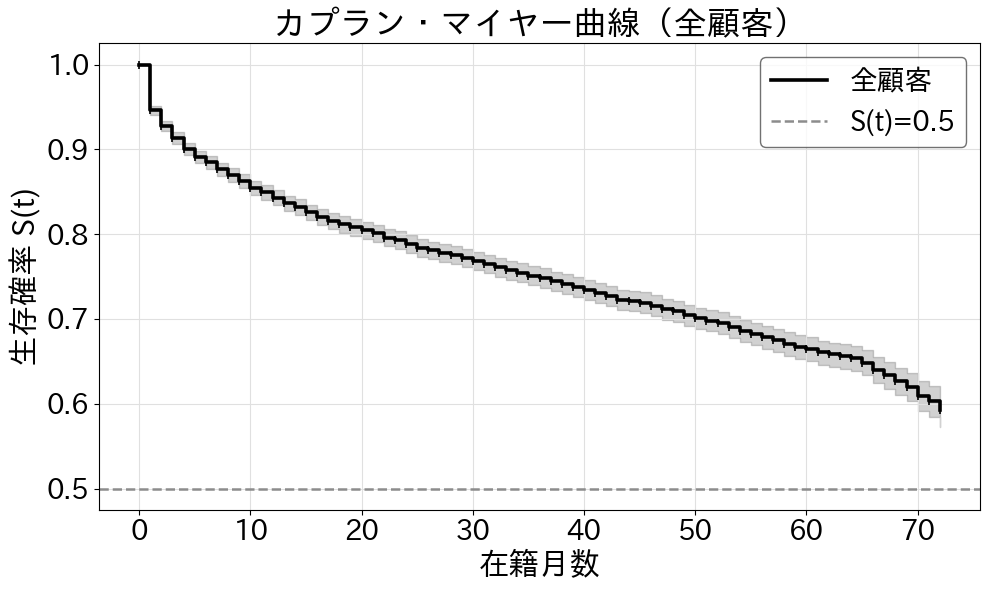

In [6]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
kmf.fit(durations=T, event_observed=E, label="全顧客")

print("カプラン・マイヤー推定の概要:")
print(f"  12か月生存確率: {kmf.survival_function_at_times(12).values[0]:.3f}")
print(f"  24か月生存確率: {kmf.survival_function_at_times(24).values[0]:.3f}")
print(f"  36か月生存確率: {kmf.survival_function_at_times(36).values[0]:.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
kmf.plot_survival_function(
    ax=ax,
    ci_show=True,
    color=MONO_BLACK,
    linewidth=2.6,
    ci_alpha=0.18,
    show_censors=True,
    censor_styles={"marker": "|", "ms": 6, "mew": 1.2},
)
ax.set_title("カプラン・マイヤー曲線（全顧客）", fontsize=24)
ax.set_xlabel("在籍月数", fontsize=22)
ax.set_ylabel("生存確率 S(t)", fontsize=22)
ax.tick_params(labelsize=20)
ax.axhline(
    y=0.5, color=MONO_MID, linestyle="--", linewidth=1.8, label="S(t)=0.5"
)
ax.grid(axis="both", color="0.88", linewidth=0.8)
ax.legend(fontsize=20, frameon=True, facecolor="white", edgecolor=MONO_DARK)
fig.tight_layout()
plt.show()

## 第7章、第3節、第2項のコード

### 契約形態ごとの生存曲線の比較

契約形態（月次・1年・2年）ごとにカプラン・マイヤー曲線を描き、ログランク検定で曲線に差があるかを確認する。

#### 処理内容

1. **契約形態ごとの推定**
   月次・1年・2年の3つのグループでそれぞれ `KaplanMeierFitter` を使い、中央生存時間と解約率を出力する。

2. **ログランク検定**
   3つの契約形態をまとめてログランク検定を実施し、p 値を確認する。

3. **曲線の描画**
   3 グループの曲線を重ね描きする。


Month-to-month: 中央生存時間 = 35.0か月, 解約率 = 0.427
One year: 中央生存時間 = infか月, 解約率 = 0.113
Two year: 中央生存時間 = infか月, 解約率 = 0.028

ログランク検定（3つの契約形態）: p値 = < 1e-300


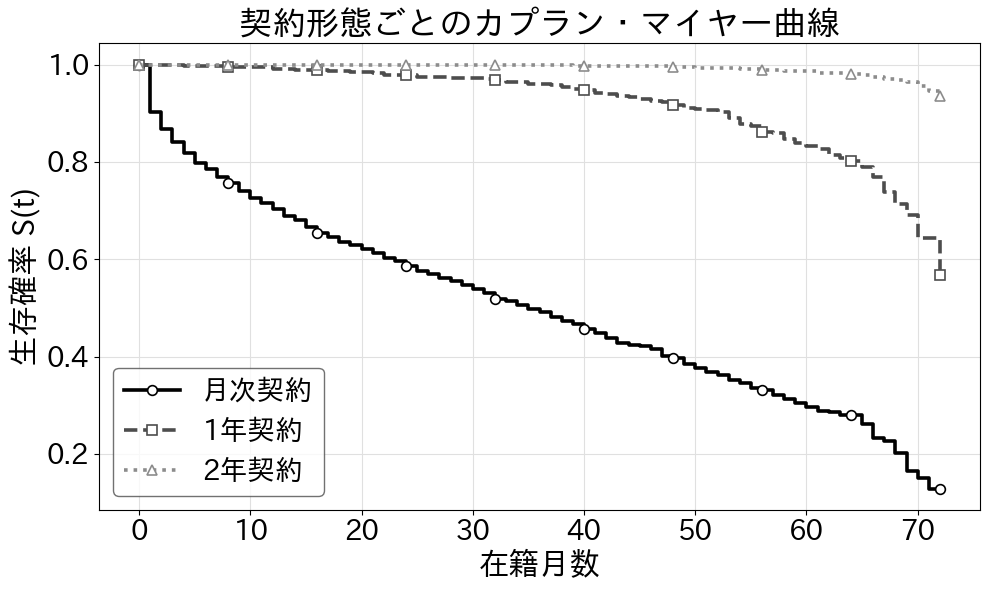

In [7]:
from lifelines.statistics import multivariate_logrank_test

fig, ax = plt.subplots(figsize=(10, 6))

contract_styles = [
    ("Month-to-month", "月次契約", MONO_BLACK, "-", "o"),
    ("One year", "1年契約", MONO_DARK, "--", "s"),
    ("Two year", "2年契約", MONO_MID, ":", "^"),
]

for contract, label, color, linestyle, marker in contract_styles:
    mask = df["Contract"] == contract
    T_g = df.filter(mask)["tenure"].to_numpy()
    E_g = df.filter(mask)["churn_flag"].to_numpy()
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(T_g, E_g, label=label)
    kmf_g.plot_survival_function(
        ax=ax,
        ci_show=False,
        color=color,
        linestyle=linestyle,
        linewidth=2.6,
        marker=marker,
        markevery=8,
        markersize=7,
        markerfacecolor="white",
        markeredgewidth=1.2,
    )

for contract in ["Month-to-month", "One year", "Two year"]:
    mask = df["Contract"] == contract
    T_g = df.filter(mask)["tenure"].to_numpy()
    E_g = df.filter(mask)["churn_flag"].to_numpy()
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(T_g, E_g)
    print(
        f"{contract}: 中央生存時間 = {kmf_g.median_survival_time_:.1f}か月, "
        f"解約率 = {E_g.mean():.3f}"
    )

# ログランク検定：3つの契約形態をまとめて比較
result = multivariate_logrank_test(T, df["Contract"].to_numpy(), E)
p_text = "< 1e-300" if result.p_value == 0 else f"{result.p_value:.4e}"
print(f"\nログランク検定（3つの契約形態）: p値 = {p_text}")

ax.set_title("契約形態ごとのカプラン・マイヤー曲線", fontsize=24)
ax.set_xlabel("在籍月数", fontsize=22)
ax.set_ylabel("生存確率 S(t)", fontsize=22)
ax.tick_params(labelsize=20)
ax.grid(axis="both", color="0.88", linewidth=0.8)
ax.legend(
    fontsize=20,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)
fig.tight_layout()
plt.show()

## 第7章、第3節、第3項のコード

### 入力項目の変換と準備

Cox比例ハザードモデル（以下、Coxモデル）への入力用に、分類を表す項目をダミー変数に変換し、Yes/No型を0/1に変換して入力項目を整える。

#### 処理内容

1. **入力項目の選択**
   `tenure`、`churn_flag` など主な9列を選び、Polarsからpandasの表に変換する。

2. **ダミー変数への変換**
   `Contract`・`InternetService`・`PaymentMethod` を `pd.get_dummies()` でダミー変数に変換する（最初の分類を基準にする）。

3. **Yes/No 列の変換**
   `Partner`・`TechSupport` を 0/1 に変換する。

4. **確認**
   変換後のデータの行数・列数と、主な6列を表示する。


In [8]:
import pandas as pd
from lifelines import CoxPHFitter

# Coxモデルに入力する項目を選び、数値に変換
features = [
    "tenure",
    "churn_flag",
    "MonthlyCharges",
    "SeniorCitizen",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "Partner",
    "TechSupport",
]

df_cox = df.select(features).to_pandas()

# 分類を表す項目をダミー変数に変換（最初の分類を基準にする）
df_cox = pd.get_dummies(
    df_cox,
    columns=["Contract", "InternetService", "PaymentMethod"],
    drop_first=True,
    dtype=int,
)

# Yes/No型の文字列列を0/1に変換
for col in ["Partner", "TechSupport"]:
    df_cox[col] = (df_cox[col] == "Yes").astype(int)

print(f"Coxモデルへの入力データ（行数, 列数）: {df_cox.shape}")

# 表示は主な6列のみ
display_cols = [
    "tenure",
    "churn_flag",
    "MonthlyCharges",
    "TechSupport",
    "Contract_One year",
    "InternetService_Fiber optic",
]
df_cox_head = df_cox[display_cols].head()
df_cox_head

Coxモデルへの入力データ（行数, 列数）: (7043, 13)


,tenure,churn_flag,MonthlyCharges,TechSupport,Contract_One year,InternetService_Fiber optic
0,1,0,29.85,0,0,0
1,34,0,56.95,0,1,0
2,2,1,53.85,0,0,0
3,45,0,42.30,1,1,0
4,2,1,70.70,0,0,1


## 第7章、第3節、第3項のコード

### Coxモデルの推定と係数の解釈

Cox比例ハザードモデルを推定し、解約のリスクと関係する入力項目を図で確認する。あわせて、比例ハザードの仮定を検定する。

#### 処理内容

1. **CoxPHFitterによる推定**
   `penalizer=0.1` を指定して係数が大きくなりすぎるのを防ぎ、`tenure` を生存時間の列、`churn_flag` を解約の有無を表す列として推定する。

2. **比例ハザードの仮定の確認**
   専用の検定を使い、時間を通じて関係が一定とみなせるかを確認する。

3. **係数と95%信頼区間の描画**
   各入力項目の係数 β_k = log(HR_k) と 95% 信頼区間を横棒グラフで描画する。


仮定に注意が必要な入力項目数: 7


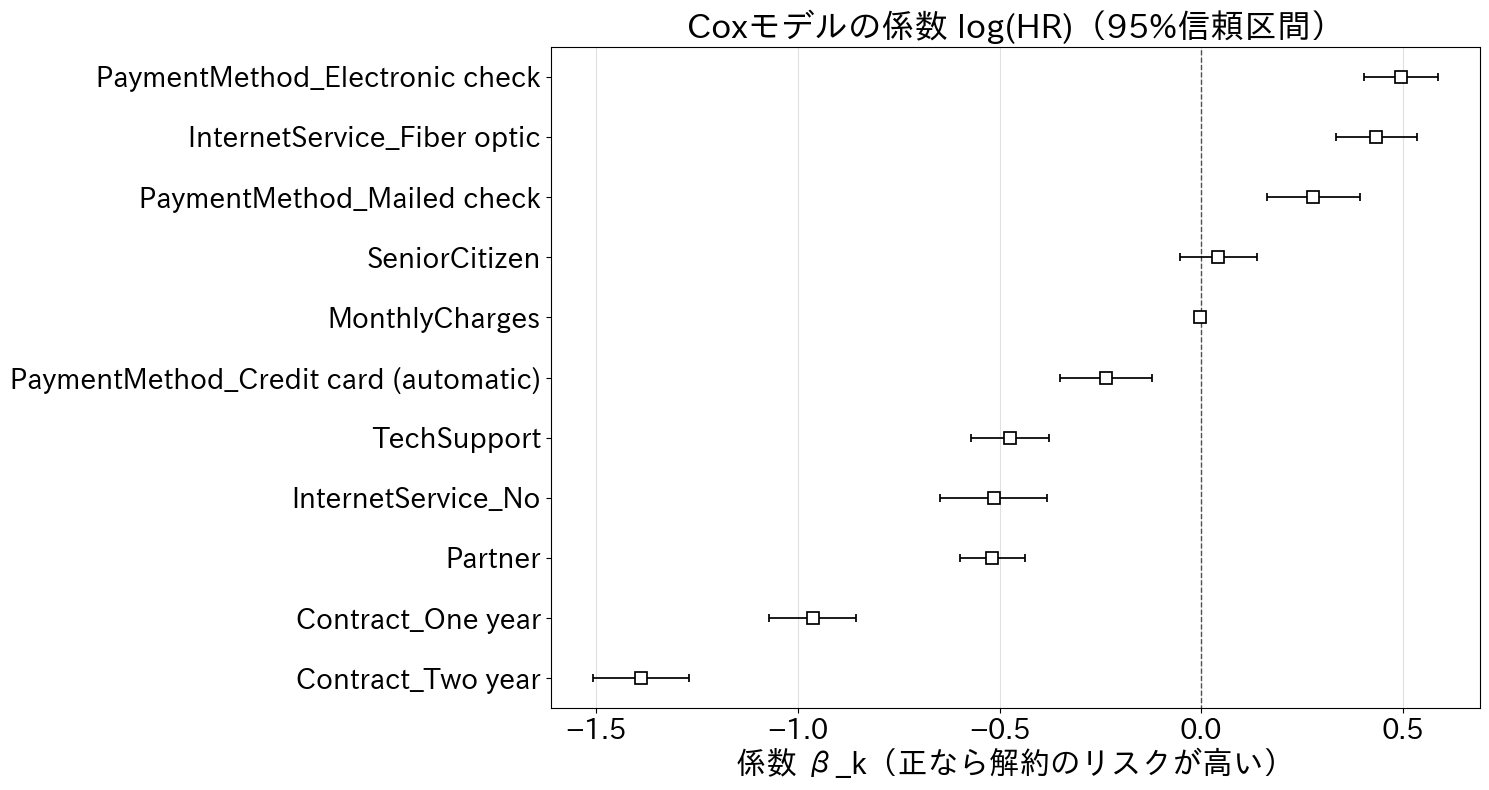

In [9]:
import matplotlib.pyplot as plt

# Coxモデルを推定
cph = CoxPHFitter(
    penalizer=0.1
)  # 係数が大きくなりすぎるのを防ぎ、計算を安定させる
cph.fit(
    df=df_cox,
    duration_col="tenure",
    event_col="churn_flag",
)

# 比例ハザードの仮定を確認
from lifelines.statistics import proportional_hazard_test

ph_test = proportional_hazard_test(cph, df_cox, time_transform="rank")
ph_warning = ph_test.summary.query("p < 0.05")
print(f"仮定に注意が必要な入力項目数: {len(ph_warning)}")

# 係数 log(HR) と95%信頼区間を描画
fig, ax = plt.subplots(figsize=(15, 8))
cph.plot(ax=ax, c=MONO_BLACK, fmt="s", markersize=8)
for line in ax.lines:
    line.set_linewidth(1.8)
ax.set_title("Coxモデルの係数 log(HR)（95%信頼区間）", fontsize=24)
ax.set_xlabel("係数 β_k（正なら解約のリスクが高い）", fontsize=22)
ax.tick_params(labelsize=20)
ax.grid(axis="x", color="0.88", linewidth=0.8)
fig.tight_layout()
plt.show()

## 第7章、第4節、第1項のコード

### 入力項目の作成

LightGBM への入力用に、分類を表す項目の変換、入力項目の追加、データの分割を行う。

#### 処理内容

1. **ダミー変数への変換**
   第3節と同様に `pd.get_dummies()` で `Contract`・`InternetService`・`PaymentMethod` をダミー変数に変換する。

2. **入力項目の追加**
   契約後1〜3か月を表す項目（`is_early_tenure`）と、月額料金×月次契約を表す項目（`monthly_x_contract_monthly`）を追加する。

3. **学習・検証・テスト分割**
   `train_test_split()` で60/20/20に分ける。解約率が各データで同じ程度になるようにし、件数と解約率を確認する。


In [10]:
import lightgbm as lgb
import numpy as np
import polars as pl
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split

# 入力項目を作り直す（第3節のdf_coxをもとに項目を追加）
df_ml = df.to_pandas()

# 分類を表す項目をダミー変数に変換
df_ml = pd.get_dummies(
    df_ml,
    columns=["Contract", "InternetService", "PaymentMethod"],
    drop_first=True,
    dtype=int,
)

# Yes/No列を0/1に変換
binary_cols = [
    "Partner",
    "TechSupport",
]
for col in binary_cols:
    if col in df_ml.columns:
        df_ml[col] = (df_ml[col] == "Yes").astype(int)

# 契約後1〜3か月を表す項目
df_ml["is_early_tenure"] = (
    (df_ml["tenure"] >= 1) & (df_ml["tenure"] <= 3)
).astype(int)

# 月額料金と月次契約の組み合わせを表す項目
contract_one_year = df_ml.get(
    "Contract_One year", pd.Series(0, index=df_ml.index)
)
contract_two_year = df_ml.get(
    "Contract_Two year", pd.Series(0, index=df_ml.index)
)
df_ml["is_month_to_month"] = (
    (contract_one_year == 0) & (contract_two_year == 0)
).astype(int)
df_ml["monthly_x_contract_monthly"] = (
    df_ml["MonthlyCharges"] * df_ml["is_month_to_month"]
)

# 入力項目と予測すべき答えを分ける
target_col = "churn_flag"
drop_cols = [target_col, "customerID", "Churn", "TotalCharges"]
feature_cols = [c for c in df_ml.columns if c not in drop_cols]

X = df_ml[feature_cols]
y = df_ml[target_col]

# 学習・検証・テスト分割（60/20/20）
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(
    f"学習データ: {len(X_train)}件, 検証データ: {len(X_val)}件, テストデータ: {len(X_test)}件"
)
print(f"学習データの解約率: {y_train.mean():.3f}")

学習データ: 4225件, 検証データ: 1409件, テストデータ: 1409件
学習データの解約率: 0.265


## 第7章、第4節、第1項のコード

### LightGBMによる解約スコアの学習

LightGBM用のデータセットを準備し、検証データの評価がよくならなくなったら学習を早めに終える仕組みを使って、解約するかどうかを分けるモデルを学習する。

#### 処理内容

1. **データセットの作成**
   `lgb.Dataset()` で学習・検証データを LightGBM 形式に変換する。

2. **設定値の指定**
   `learning_rate=0.05`、`num_leaves=31` など、解約の分類に使う最初の設定値を指定する。

3. **モデルの学習**
   `lgb.train()` で学習回数を最大500回とし、評価が50回続けて改善しなければ学習を終えて、最適な学習回数を決める。


In [11]:
# LightGBM用のデータセット
dtrain = lgb.Dataset(X_train, label=y_train)
dval = lgb.Dataset(X_val, label=y_val, reference=dtrain)

# 解約の分類に使う設定値
params = {
    "objective": "binary",
    "metric": ["auc", "binary_logloss"],
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 20,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "reg_alpha": 0.1,
    "reg_lambda": 0.1,
    "verbose": -1,
    "random_state": 42,
}

callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=False),
    lgb.log_evaluation(period=100),
]

model = lgb.train(
    params=params,
    train_set=dtrain,
    num_boost_round=500,
    valid_sets=[dval],
    callbacks=callbacks,
)

print(f"最適な学習回数: {model.best_iteration}")

[100]	valid_0's auc: 0.843985	valid_0's binary_logloss: 0.417583
最適な学習回数: 61


## 第7章、第4節、第1項のコード

### モデル評価とスコアの確認

テストデータの解約スコアを求め、ROC-AUC・APによる評価と、各入力項目が使われた度合いをグラフで確認する。

#### 処理内容

1. **予測と評価**
   テストデータに対して `model.predict()` で解約スコアを求め、ROC-AUCとAPを求める。

2. **各入力項目が使われた度合いの整理**
   Gainをもとに各入力項目が使われた度合いをPolarsの表にまとめ、上位10件を取り出す。

3. **棒グラフの描画**
   各入力項目が使われた度合いを水平棒グラフで示する。


テストデータの評価:
  ROC-AUC:  0.8298
  AP:       0.6226


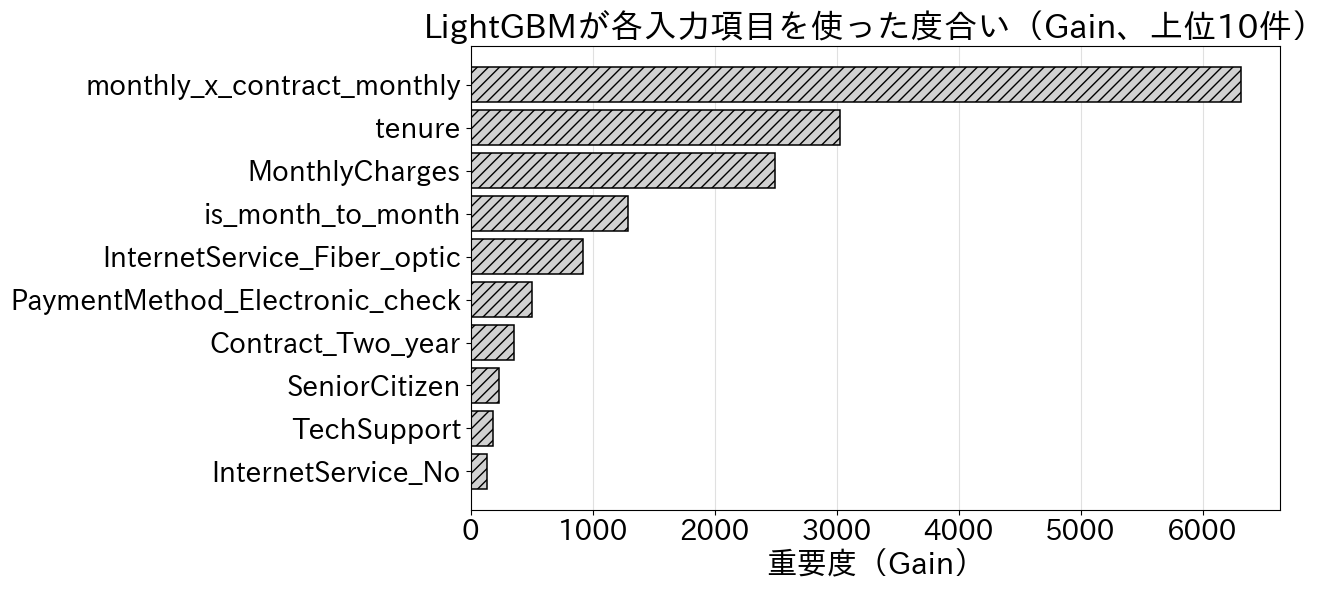

In [12]:
# テストデータで評価
y_pred_proba = model.predict(X_test)

roc_auc = roc_auc_score(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

print("テストデータの評価:")
print(f"  ROC-AUC:  {roc_auc:.4f}")
print(f"  AP:       {average_precision:.4f}")

# 各入力項目が使われた度合い（上位10件）
import matplotlib.pyplot as plt

importance_df = (
    pl.DataFrame(
        {
            "feature": model.feature_name(),
            "importance": model.feature_importance(importance_type="gain"),
        }
    )
    .sort("importance", descending=True)
    .head(10)
)

fig, ax = plt.subplots(figsize=(13, 6))
ax.barh(
    importance_df["feature"].to_list()[::-1],
    importance_df["importance"].to_list()[::-1],
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    linewidth=1.1,
    hatch="///",
)
ax.set_title(
    "LightGBMが各入力項目を使った度合い（Gain、上位10件）", fontsize=24
)
ax.set_xlabel("重要度（Gain）", fontsize=22)
ax.tick_params(labelsize=20)
ax.grid(axis="x", color="0.88", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 第7章、第4節、第2項のコード

### 閾値の設定と適合率・再現率の関係

検証データでF1スコアが最大になる閾値を探し、同じ閾値をテストデータに適用して評価する。

#### 処理内容

1. **適合率と再現率の関係を示す曲線の計算**
   検証データの予測結果から `precision_recall_curve()` で各閾値の適合率・再現率・F1スコアを計算する。

2. **F1スコアが最大になる閾値を探す**
   F1スコアが最大になる閾値 `best_threshold` を探し、テストデータへの適用結果を出力する。

3. **2つの図の描画**
   左図に適合率と再現率の関係を示す曲線、右図に閾値ごとの適合率・再現率・F1スコアの変化を描き。


F1スコアが最大になる閾値（検証データ）: 0.359
  Validation Precision: 0.599
  Validation Recall:    0.719
  Validation F1 Score:  0.654

同じ閾値をテストデータに適用:
  Test Precision: 0.548
  Test Recall:    0.674
  Test F1 Score:  0.604


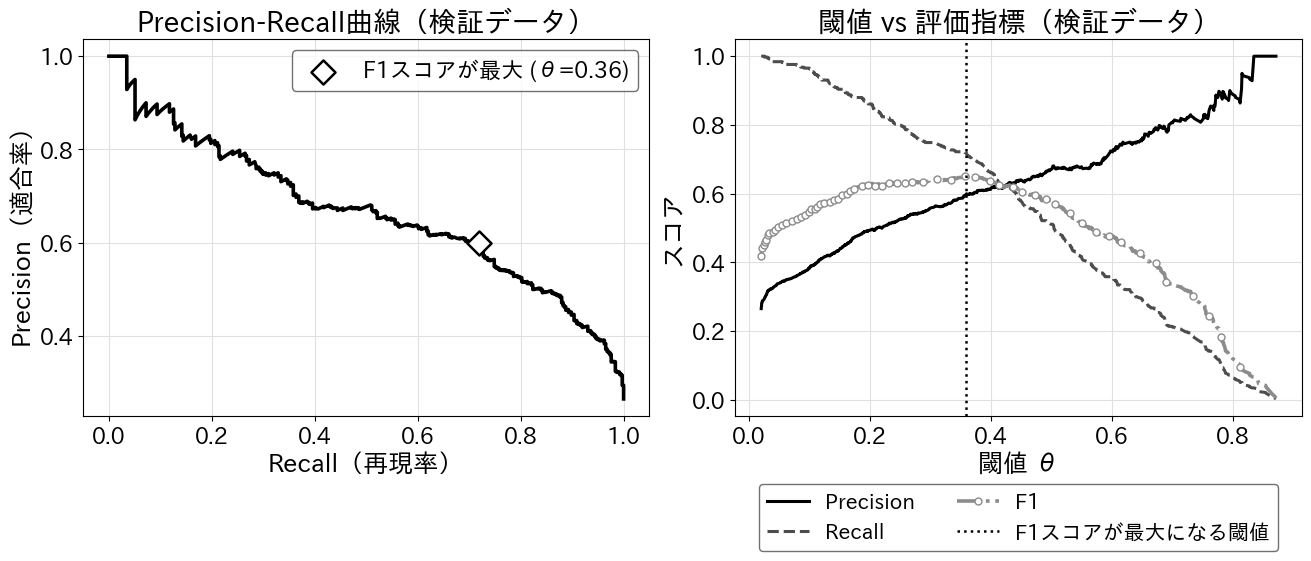

In [13]:
import matplotlib.pyplot as plt
import polars as pl
from sklearn.metrics import (
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

# 閾値は検証データで決め、テストデータは最終評価に使う
y_val_pred_proba = model.predict(X_val)
precisions, recalls, thresholds = precision_recall_curve(
    y_val, y_val_pred_proba
)

# F1スコアが最大になる閾値を探す
f1_scores = (
    2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-8)
)
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

y_test_pred = (y_pred_proba >= best_threshold).astype(int)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"F1スコアが最大になる閾値（検証データ）: {best_threshold:.3f}")
print(f"  Validation Precision: {precisions[best_idx]:.3f}")
print(f"  Validation Recall:    {recalls[best_idx]:.3f}")
print(f"  Validation F1 Score:  {f1_scores[best_idx]:.3f}")
print("\n同じ閾値をテストデータに適用:")
print(f"  Test Precision: {test_precision:.3f}")
print(f"  Test Recall:    {test_recall:.3f}")
print(f"  Test F1 Score:  {test_f1:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

# 左：検証データのPR曲線
axes[0].plot(recalls, precisions, color=MONO_BLACK, linewidth=2.6)
axes[0].scatter(
    recalls[best_idx],
    precisions[best_idx],
    facecolor="white",
    edgecolor=MONO_BLACK,
    linewidth=1.8,
    marker="D",
    s=150,
    zorder=5,
    label=f"F1スコアが最大 (θ={best_threshold:.2f})",
)
axes[0].set_xlabel("Recall（再現率）", fontsize=18)
axes[0].set_ylabel("Precision（適合率）", fontsize=18)
axes[0].set_title("Precision-Recall曲線（検証データ）", fontsize=20)
axes[0].tick_params(labelsize=16)
axes[0].grid(color="0.88", linewidth=0.8)
axes[0].legend(
    fontsize=16, frameon=True, facecolor="white", edgecolor=MONO_DARK
)

# 右：検証データでの閾値ごとのF1・Precision・Recall
axes[1].plot(
    thresholds,
    precisions[:-1],
    label="Precision",
    color=MONO_BLACK,
    linewidth=2.2,
)
axes[1].plot(
    thresholds,
    recalls[:-1],
    label="Recall",
    color=MONO_DARK,
    linestyle="--",
    linewidth=2.2,
)
axes[1].plot(
    thresholds,
    f1_scores,
    label="F1",
    color=MONO_MID,
    linestyle="-.",
    linewidth=2.6,
    marker="o",
    markevery=20,
    markersize=5,
    markerfacecolor="white",
)
axes[1].axvline(
    x=best_threshold,
    color=MONO_BLACK,
    linestyle=":",
    linewidth=1.8,
    label="F1スコアが最大になる閾値",
)
axes[1].set_xlabel("閾値 θ", fontsize=18)
axes[1].set_ylabel("スコア", fontsize=18)
axes[1].set_title("閾値 vs 評価指標（検証データ）", fontsize=20)
axes[1].tick_params(labelsize=16)
axes[1].grid(color="0.88", linewidth=0.8)
axes[1].legend(
    fontsize=15,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    borderaxespad=0,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)

plt.show()

## 第7章、第4節、第2項のコード

### 施策の対象リストの作成

テストデータに解約スコアを付け、スコアが高い順に施策の対象リストを作成する。

#### 処理内容

1. **解約スコアを付ける**
   テストデータの顧客ID・解約スコア・実際に解約したかを表す値をPolarsの表にまとめ、スコアが高い順に並べる。

2. **施策の対象となる顧客数の集計**
   `best_threshold` 以上の顧客数とその割合を出力する。

3. **上位顧客の表示**
   `action_list.head(20)` で解約スコアの上位20件を確認する。


In [14]:
# テストデータに解約スコアを付ける
customer_ids_test = df_ml.loc[X_test.index, "customerID"].astype(str).to_list()
action_list = pl.DataFrame(
    {
        "customerID": customer_ids_test,
        "churn_score": y_pred_proba,
        "actual_churn": y_test.values,
    }
).sort("churn_score", descending=True)

# 検証データで決めた閾値以上を施策の対象にする
n_target = (action_list["churn_score"] >= best_threshold).sum()
print(
    f"施策の対象となる顧客数: {n_target}名 / 全{len(action_list)}名 ({n_target / len(action_list) * 100:.1f}%)"
)

# 本文掲載用には上位5件を保存し、実行結果では上位20件を表示
action_list_top5 = action_list.head(5).with_columns(
    pl.col("churn_score").round(3)
)
print("\n解約スコア上位顧客リスト（上位20件）:")
action_list.head(20)

施策の対象となる顧客数: 460名 / 全1409名 (32.6%)

解約スコア上位顧客リスト（上位20件）:


customerID,churn_score,actual_churn
str,f64,i32
"""9300-AGZNL""",0.866273,1
"""6567-HOOPW""",0.863087,1
"""7493-TPUWZ""",0.8599,1
"""2514-GINMM""",0.8599,1
"""0495-RVCBF""",0.8599,1
…,…,…
"""4445-ZJNMU""",0.829494,0
"""9223-UCPVT""",0.82449,1
"""4713-LZDRV""",0.820944,1


## 第7章、第4節、第2項のコード

### 解約した顧客が上位に集まっている割合の確認（リフト曲線・累積ゲイン曲線）

生成した解約スコアで、解約した顧客をどれだけ上位に集められたかを、累積ゲイン曲線とリフト曲線で確認する。

#### 処理内容

1. **累積ゲインの計算**
   解約スコアが高い順に並べた結果から、解約した顧客を見つけられた割合を計算する。

2. **上位20%で見つけられる割合を書き添える**
   上位20%で見つけられる割合を計算し、グラフに書き添える。

3. **2つの図の描画**
   左図に累積ゲイン曲線、右図にリフト曲線を描画する。


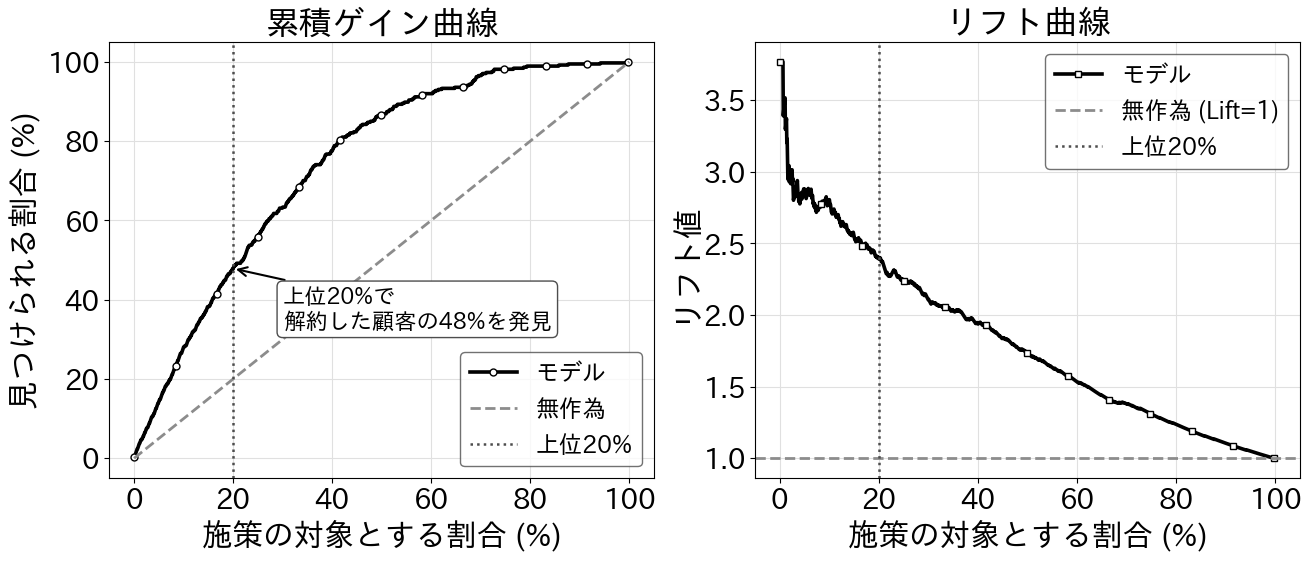

In [15]:
# 解約スコアが高い順に並べた結果から累積ゲインを計算
sorted_labels = action_list["actual_churn"].to_numpy()
n_total = len(sorted_labels)
n_churners = sorted_labels.sum()

cum_gain = np.cumsum(sorted_labels) / n_churners
random_line = np.arange(1, n_total + 1) / n_total

# 上位20%での累積ゲイン（0始まり添字に合わせて1件戻す）
top_20 = int(np.ceil(n_total * 0.20))
gain_at_20 = cum_gain[top_20 - 1] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

# 累積ゲイン曲線
x_axis = np.arange(1, n_total + 1) / n_total * 100
axes[0].plot(
    x_axis,
    cum_gain * 100,
    color=MONO_BLACK,
    linewidth=2.6,
    marker="o",
    markevery=max(1, n_total // 12),
    markersize=5,
    markerfacecolor="white",
    label="モデル",
)
axes[0].plot(
    [0, 100],
    [0, 100],
    color=MONO_MID,
    linestyle="--",
    linewidth=2.0,
    label="無作為",
)
axes[0].axvline(
    x=20, color=MONO_DARK, linestyle=":", linewidth=1.8, label="上位20%"
)
axes[0].annotate(
    f"上位20%で\n解約した顧客の{gain_at_20:.0f}%を発見",
    xy=(20, gain_at_20),
    xytext=(30, gain_at_20 - 15),
    arrowprops={"arrowstyle": "->", "color": MONO_BLACK, "linewidth": 1.5},
    color=MONO_BLACK,
    fontsize=16,
    bbox={
        "boxstyle": "round,pad=0.25",
        "facecolor": "white",
        "edgecolor": MONO_DARK,
    },
)
axes[0].set_title("累積ゲイン曲線", fontsize=24)
axes[0].set_xlabel("施策の対象とする割合 (%)", fontsize=22)
axes[0].set_ylabel("見つけられる割合 (%)", fontsize=22)
axes[0].tick_params(labelsize=20)
axes[0].grid(color="0.88", linewidth=0.8)
axes[0].legend(
    fontsize=17,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
)

# リフト曲線
lift = cum_gain / random_line
axes[1].plot(
    x_axis,
    lift,
    color=MONO_BLACK,
    linewidth=2.6,
    marker="s",
    markevery=max(1, n_total // 12),
    markersize=5,
    markerfacecolor="white",
    label="モデル",
)
axes[1].axhline(
    y=1, color=MONO_MID, linestyle="--", linewidth=2.0, label="無作為 (Lift=1)"
)
axes[1].axvline(
    x=20, color=MONO_DARK, linestyle=":", linewidth=1.8, label="上位20%"
)
axes[1].set_title("リフト曲線", fontsize=24)
axes[1].set_xlabel("施策の対象とする割合 (%)", fontsize=22)
axes[1].set_ylabel("リフト値", fontsize=22)
axes[1].tick_params(labelsize=20)
axes[1].grid(color="0.88", linewidth=0.8)
axes[1].legend(
    fontsize=17, frameon=True, facecolor="white", edgecolor=MONO_DARK
)

plt.show()

## 第7章、第4節、第2項のコード

### 上位10%・20%で見つけられる割合の確認

テストデータで解約スコアの上位10%・20%を選んだ場合に、解約した顧客を何割見つけられるかを数値で出力する。

#### 処理内容

1. **上位 10%・20% の件数計算**
   テストデータ全体の10%・20%に相当する件数を求める。

2. **見つけられる割合の出力**
   各割合で見つけられる割合を表示する。


In [16]:
top_10 = int(np.ceil(n_total * 0.10))
top_20 = int(np.ceil(n_total * 0.20))

print(f"\n上位10%で見つけられる割合: {cum_gain[top_10 - 1] * 100:.1f}%")
print(f"上位20%で見つけられる割合: {cum_gain[top_20 - 1] * 100:.1f}%")


上位10%で見つけられる割合: 28.1%
上位20%で見つけられる割合: 47.9%
